# <font color='yellow'>Segmentación de tumores cerebrales en MRI usando U-Net</font>




# 0. Setea un entorno con GPU


#1. Descarga y Visualización de datos


In [ ]:
!gdown  https://drive.google.com/uc?id=1_eVfbtPdjJWAmb1aUrfHHUjo5XjRegfo
!unzip -qq mri_brain_data.zip


Downloading...
From (original): https://drive.google.com/uc?id=1_eVfbtPdjJWAmb1aUrfHHUjo5XjRegfo
From (redirected): https://drive.google.com/uc?id=1_eVfbtPdjJWAmb1aUrfHHUjo5XjRegfo&confirm=t&uuid=5cfb3e78-0acc-469e-8964-f20e41663190
To: /content/mri_brain_data.zip
100% 87.8M/87.8M [00:00<00:00, 116MB/s]


In [ ]:
# Importa módulos necesarios
import os                          # Para manejar rutas y archivos del sistema
import numpy as np                 # Para operaciones numéricas y manipulación de matrices
from PIL import Image              # Para abrir y procesar imágenes
from pycocotools.coco import COCO  # Para trabajar con anotaciones en formato COCO
import tensorflow as tf            # Para futuras tareas con redes neuronales (no se usa aquí directamente)

# Define las rutas a los directorios de entrenamiento y validación
train_dir = '/content/train'
val_dir = '/content/valid'

# Define las rutas a los archivos de anotaciones en formato COCO
train_ann_file = os.path.join(train_dir, '_annotations.coco.json')
val_ann_file = os.path.join(val_dir, '_annotations.coco.json')

# Carga las anotaciones COCO para entrenamiento y validación
train_coco = COCO(train_ann_file)
val_coco = COCO(val_ann_file)

# Función para cargar una imagen y su máscara correspondiente usando anotaciones COCO
def load_image_and_mask(coco, image_dir, image_id):
    # Obtiene la información de la imagen (nombre de archivo, alto, ancho, etc.)
    image_info = coco.loadImgs(image_id)[0]

    # Construye la ruta completa al archivo de imagen
    image_path = os.path.join(image_dir, image_info['file_name'])

    # Abre la imagen, la convierte a RGB y la transforma en un array NumPy
    image = Image.open(image_path).convert('RGB')
    image = np.array(image)

    # Inicializa una máscara vacía (todo ceros) con el mismo alto y ancho que la imagen
    mask = np.zeros((image_info['height'], image_info['width']), dtype=np.uint8)

    # Obtiene los IDs de anotaciones asociadas a esta imagen
    ann_ids = coco.getAnnIds(imgIds=image_id)

    # Carga las anotaciones correspondientes
    anns = coco.loadAnns(ann_ids)

    # Para cada anotación, convierte la anotación a una máscara binaria y la combina con la máscara actual
    for ann in anns:
        mask = np.maximum(mask, coco.annToMask(ann))  # Superpone las máscaras de diferentes objetos

    # Devuelve la imagen y la máscara asociada
    return image, mask

# Obtiene la lista de IDs de imágenes en el conjunto de entrenamiento
train_img_ids = train_coco.getImgIds()

# Visualiza las primeras 5 imágenes y sus máscaras
for i in range(5):
    img_id = train_img_ids[i]  # Obtiene el ID de la imagen en la posición i
    img, mask = load_image_and_mask(train_coco, train_dir, img_id)  # Carga imagen y máscara
    print(f"Image {i} shape:", img.shape, "Mask shape:", mask.shape)  # Imprime las dimensiones de la imagen y la máscara


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Image 0 shape: (640, 640, 3) Mask shape: (640, 640)
Image 1 shape: (640, 640, 3) Mask shape: (640, 640)
Image 2 shape: (640, 640, 3) Mask shape: (640, 640)
Image 3 shape: (640, 640, 3) Mask shape: (640, 640)
Image 4 shape: (640, 640, 3) Mask shape: (640, 640)


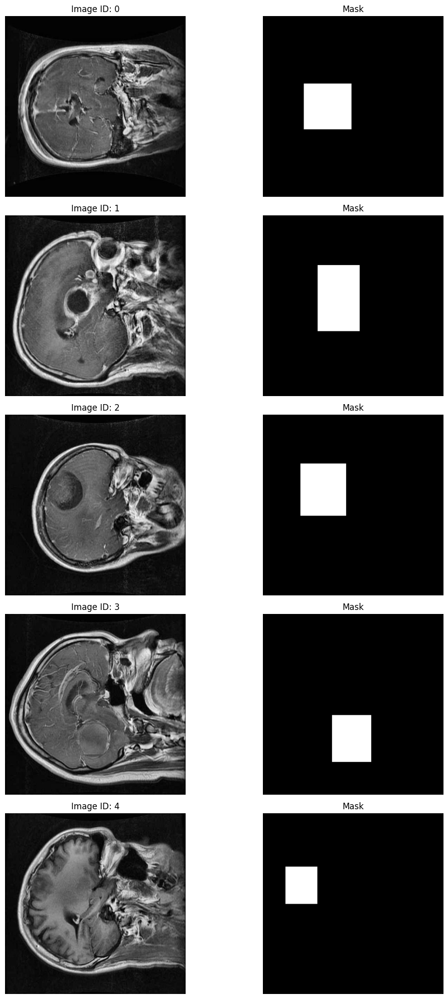

In [ ]:
import matplotlib.pyplot as plt  # Importa la librería para graficar

# Función para mostrar imágenes junto con sus máscaras de segmentación
def plot_images_and_masks(coco, image_dir, num_samples=5):
    img_ids = coco.getImgIds()  # Obtiene todos los IDs de imágenes del dataset COCO

    plt.figure(figsize=(12, num_samples * 4))  # Define el tamaño de la figura para los subplots

    for i in range(num_samples):  # Itera sobre la cantidad de muestras que se quieren mostrar
        img_id = img_ids[i]  # Obtiene el ID de imagen en la posición i
        image, mask = load_image_and_mask(coco, image_dir, img_id)  # Carga la imagen y su máscara

        # Primer subplot: muestra la imagen
        plt.subplot(num_samples, 2, 2*i + 1)  # Ubica el subplot (filas, columnas, posición)
        plt.imshow(image)  # Muestra la imagen RGB
        plt.title(f"Image ID: {img_id}")  # Título con el ID de imagen
        plt.axis('off')  # Oculta los ejes

        # Segundo subplot: muestra la máscara correspondiente
        plt.subplot(num_samples, 2, 2*i + 2)  # Ubica el subplot siguiente
        plt.imshow(mask, cmap='gray')  # Muestra la máscara en escala de grises
        plt.title("Mask")  # Título
        plt.axis('off')  # Oculta los ejes

    plt.tight_layout()  # Ajusta automáticamente los espacios entre subplots
    plt.show()  # Muestra la figura con todas las imágenes y máscaras

plot_images_and_masks(train_coco, train_dir, num_samples=5)

#2. Data Augmentation
Estas transformaciones ayudan a aumentar la diversidad del conjunto de datos de entrenamiento sin necesidad de recolectar más datos.

Se aplican simultáneamente a imágenes y máscaras para tareas como segmentación semántica, asegurando que las máscaras sigan alineadas correctamente con sus imágenes.

In [ ]:
import albumentations as A  # albumentations realiza transformaciones en imágenes
from albumentations.pytorch import ToTensorV2  # Utilizado para convertir a tensores de PyTorch

# Define una pipeline de aumentos para aplicar tanto a la imagen como a la máscara correspondiente
augmentation = A.Compose([  # 'Compose' agrupa varias transformaciones
    A.HorizontalFlip(p=0.5),  # 50% de probabilidad de voltear horizontalmente
    A.VerticalFlip(p=0.5),  # 50% de probabilidad de voltear verticalmente
    A.RandomRotate90(p=0.5),  # 50% de probabilidad de rotar la imagen 90°, 180° o 270°
    A.ShiftScaleRotate(       # Aplica desplazamiento, escalado y rotación aleatorios
        shift_limit=0.05,     # Desplazamiento de hasta ±5%
        scale_limit=0.05,     # Escalado de hasta ±5%
        rotate_limit=15,      # Rotación aleatoria de hasta ±15 grados
        p=0.5                 # 50% de probabilidad de aplicar esta transformación
    ),
    A.RandomBrightnessContrast(p=0.2),  # Cambios aleatorios de brillo y contraste con 20% de probabilidad
],
    additional_targets={'mask': 'mask'}  # Esto indica que las transformaciones deben aplicarse también a las máscaras (sin alterar su significado)
)

# Función para aplicar augmentación a imagen y máscara
def augment_image_and_mask(image, mask):
    # Ejecuta el pipeline de augmentación definido previamente (por ejemplo, con Albumentations)
    augmented = augmentation(image=image, mask=mask)

    # Devuelve la imagen y la máscara aumentadas
    return augmented['image'], augmented['mask']

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


##2.1 Ejemplo de aumento de datos

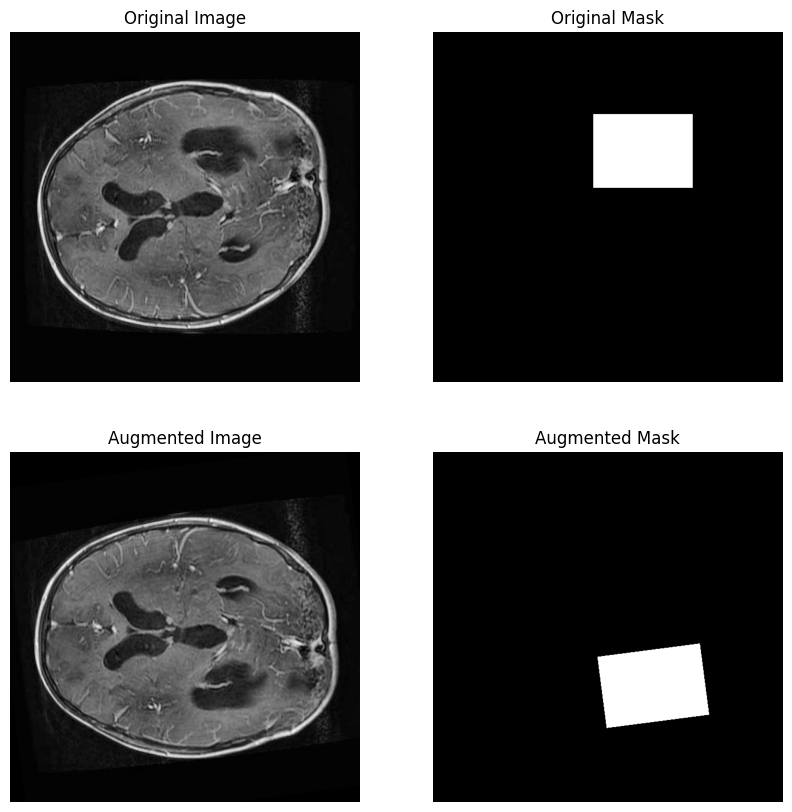

In [ ]:
# Obtener la primera imagen y su máscara del conjunto de entrenamiento
img_id = train_coco.getImgIds()[5]
image, mask = load_image_and_mask(train_coco, train_dir, img_id)

# Aplicar augmentación
aug_img, aug_mask = augment_image_and_mask(image, mask)

# Visualizar imagen original y aumentada junto a sus máscaras
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0,0].imshow(image)
axes[0,0].set_title('Original Image')
axes[0,0].axis('off')

axes[0,1].imshow(mask, cmap='gray')
axes[0,1].set_title('Original Mask')
axes[0,1].axis('off')

axes[1,0].imshow(aug_img)
axes[1,0].set_title('Augmented Image')
axes[1,0].axis('off')

axes[1,1].imshow(aug_mask, cmap='gray')
axes[1,1].set_title('Augmented Mask')
axes[1,1].axis('off')

plt.show()

#3.Preprocesamiento

In [ ]:
import cv2
import numpy as np

# Función para preprocesar una imagen y su máscara correspondiente
def preprocess_image_and_mask(image, mask, img_size=(128, 128)):

    # Si la imagen es RGB (3 canales), se convierte a escala de grises
    if image.ndim == 3 and image.shape[-1] == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  # También puede usarse BGR2GRAY si cv2.imread() se usó con imágenes en BGR

    # Redimensiona la imagen al tamaño deseado (por defecto 128x128)
    image = cv2.resize(image, img_size)

    # Redimensiona la máscara al mismo tamaño, usando interpolación 'nearest' para mantener los valores de clase sin difuminar
    mask = cv2.resize(mask, img_size, interpolation=cv2.INTER_NEAREST)

    # Normaliza los valores de la imagen al rango [0, 1]
    image = image / 255.0

    # Convierte la máscara a binaria: todo valor > 0 se vuelve 1 (útil para segmentación binaria)
    mask = (mask > 0).astype(np.float32)

    # Expande la dimensión del canal para que quede con shape (H, W, 1) — necesario para modelos CNN
    image = np.expand_dims(image, axis=-1)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask





#3.1 Visualización de preprocesamiento

Original Size:  (640, 640, 3) (640, 640)
Preprocessed Size:  (128, 128, 1) (128, 128, 1)


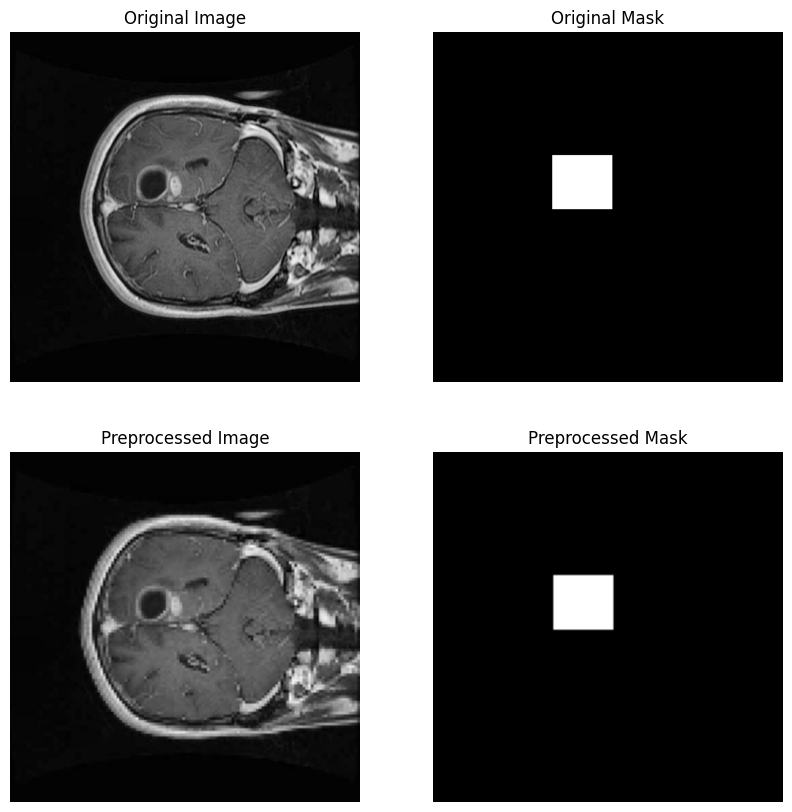

In [ ]:
# Obtener la primera imagen y su máscara del conjunto de entrenamiento
img_id = train_coco.getImgIds()[10]
image, mask = load_image_and_mask(train_coco, train_dir, img_id)

# Aplicar preprocesamiento
pproc_img, pproc_mask = preprocess_image_and_mask(image, mask)

print("Original Size: ", image.shape, mask.shape)
print("Preprocessed Size: ", pproc_img.shape, pproc_mask.shape)

# Visualizar imagen original y aumentada junto a sus máscaras
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0,0].imshow(image)
axes[0,0].set_title('Original Image')
axes[0,0].axis('off')

axes[0,1].imshow(mask, cmap='gray')
axes[0,1].set_title('Original Mask')
axes[0,1].axis('off')

axes[1,0].imshow(pproc_img[:,:,0], cmap='gray')
axes[1,0].set_title('Preprocessed Image')
axes[1,0].axis('off')

axes[1,1].imshow(pproc_mask, cmap='gray')
axes[1,1].set_title('Preprocessed Mask')
axes[1,1].axis('off')

plt.show()

#4. Generador de datos

In [ ]:
import random
def data_generator(coco, image_dir, batch_size=16, augment_func=None, img_size=(128,128), subset_fraction=1.0, seed=21):

    if not (0 < subset_fraction <= 1.0):
        raise ValueError(
            f"subset_fraction debe ser un valor entre (0, 1], actualmente es {subset_fraction}"
        )

    # Obtiene todos los IDs de imágenes del conjunto COCO
    img_ids = coco.getImgIds()

    # Se escoge tamaño del conjunto de entrenamiento
    rng = np.random.default_rng(seed)
    rng.shuffle(img_ids)
    k = int(len(img_ids) * subset_fraction)
    img_ids = img_ids[:k]

    # Cuenta total de imágenes disponibles
    n = len(img_ids)

    # Bucle infinito para que el generador pueda usarse continuamente en entrenamiento (ej. con model.fit)
    while True:
        # Mezcla aleatoriamente los IDs de imágenes antes de cada epoch
        rng.shuffle(img_ids)

        # Procesa imágenes en lotes del tamaño batch_size
        for i in range(0, n, batch_size):
            # Selecciona un subconjunto de IDs correspondiente al batch actual
            batch_ids = img_ids[i:i+batch_size]

            # Listas vacías donde se almacenarán las imágenes y máscaras procesadas
            images = []
            masks = []

            # Recorre cada imagen en el batch
            for img_id in batch_ids:
                # Carga la imagen y su máscara correspondiente
                img, mask = load_image_and_mask(coco, image_dir, img_id)

                # Si se proporcionó una función de augmentación, se aplica a la imagen y máscara
                if augment_func:
                    img, mask = augment_func(img, mask)

                # Preprocesa la imagen y máscara (escalar, redimensionar, normalizar, etc.)
                img, mask = preprocess_image_and_mask(img, mask, img_size)

                # Agrega los resultados a las listas del batch
                images.append(img)
                masks.append(mask)

            # Convierte listas a arrays NumPy y los entrega como output del generador
            yield np.array(images, dtype=np.float32), np.array(masks, dtype=np.float32)

#5. Definición de la Red U-Net

In [ ]:
from tensorflow.keras import layers, models  # Importa las capas y herramientas para construir modelos de Keras

def build_unet(input_shape=(128, 128, 1)):
    # Define la entrada del modelo con forma 128x128 y 1 canal (imagen en escala de grises)
    inputs = layers.Input(input_shape)

    # --- Encoder: Contracción (extracción de características) ---

    # Primer bloque de convoluciones: 2 convoluciones de 64 filtros con activación ReLU
    c1 = layers.Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)  # Reduce tamaño a la mitad

    # Segundo bloque
    c2 = layers.Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # Tercer bloque
    c3 = layers.Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # Cuarto bloque
    c4 = layers.Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # --- Bottleneck: capa intermedia más profunda ---
    c5 = layers.Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, 3, activation='relu', padding='same')(c5)

    # --- Decoder: Expansión (reconstrucción del tamaño original) ---

    # Primer bloque de expansión: upsampling + concatenación con c4
    u6 = layers.UpSampling2D((2, 2))(c5)  # Duplica el tamaño espacial
    u6 = layers.concatenate([u6, c4])     # Skip connection con encoder
    c6 = layers.Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512, 3, activation='relu', padding='same')(c6)

    # Segundo bloque de expansión
    u7 = layers.UpSampling2D((2, 2))(c6)
    u7 = layers.concatenate([u7, c3])
    c7 = layers.Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256, 3, activation='relu', padding='same')(c7)

    # Tercer bloque de expansión
    u8 = layers.UpSampling2D((2, 2))(c7)
    u8 = layers.concatenate([u8, c2])
    c8 = layers.Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128, 3, activation='relu', padding='same')(c8)

    # Cuarto bloque de expansión
    u9 = layers.UpSampling2D((2, 2))(c8)
    u9 = layers.concatenate([u9, c1])
    c9 = layers.Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64, 3, activation='relu', padding='same')(c9)

    # --- Output: Capa de predicción ---
    # Usa un filtro 1x1 para mapear a 1 canal de salida, activación sigmoide para segmentación binaria
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c9)

    # Crea el modelo completo conectando entrada y salida
    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model  # Retorna el modelo listo para compilar y entrenar


#6. Métricas relevantes para evaluar el entrenamiento

In [ ]:
import tensorflow.keras.backend as K  # Importa funciones backend de Keras para operaciones tensoriales compatibles con TensorFlow

# --- Métrica IoU (Intersection over Union) ---
def iou_metric(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)  # Aplana el tensor de etiquetas verdaderas a 1D
    y_pred_f = K.flatten(y_pred)  # Aplana el tensor de predicciones a 1D
    intersection = K.sum(y_true_f * y_pred_f)  # Calcula la intersección entre las máscaras
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection  # Calcula la unión (suma de áreas menos la intersección)
    return (intersection + smooth) / (union + smooth)  # Devuelve IoU con suavizado para evitar división por cero

# --- Métrica Dice Coefficient ---
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)  # Aplana etiquetas verdaderas
    y_pred_f = K.flatten(y_pred)  # Aplana predicciones
    intersection = K.sum(y_true_f * y_pred_f)  # Intersección de las máscaras
    # Fórmula del Dice Coefficient: 2 * intersección / (área total de ambas máscaras)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# --- Función de pérdida basada en Dice ---
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)  # La pérdida es 1 - dice_coef (cuanto menor el coeficiente, mayor la pérdida)

# --- Pérdida combinada: Dice Loss + Binary Cross Entropy ---
def combined_loss(y_true, y_pred):
    dice = dice_loss(y_true, y_pred)  # Calcula Dice Loss
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)  # Calcula Binary Cross Entropy
    # Combina ambas pérdidas con pesos: 60% Dice Loss y 40% BCE
    return 0.6 * dice + 0.4 * bce


#7. Entrenamiento

In [ ]:
initial_learning_rate = 1e-4
optimizer = tf.keras.optimizers.Adam(learning_rate=initial_learning_rate)

In [ ]:
model = build_unet(input_shape=(128,128,1))
model.compile(optimizer=optimizer, loss=combined_loss, metrics=[dice_coef, iou_metric, "accuracy"])

In [ ]:
subset_fraction = 0.5 #Pocentaje del conjunto de entrenamiento que se usará
batch_size = 16 #tamaño del batch a utilizar

In [ ]:
# Crea el generador de datos para el conjunto de entrenamiento.
# Se especifica el uso de una función de aumento de datos (augment_image_and_mask).
train_gen = data_generator(train_coco, train_dir, batch_size=batch_size, augment_func=augment_image_and_mask, subset_fraction=subset_fraction)

# Crea el generador de datos para el conjunto de validación.
# Aquí no se aplica ningún aumento de datos (augment_func=None).
val_gen = data_generator(val_coco, val_dir, batch_size=batch_size, augment_func=None)

n_train_total = len(train_coco.getImgIds())
n_train_subset = int(n_train_total * subset_fraction)

# Calcula cuántos pasos (batches) hay por época durante el entrenamiento.
# Se divide la cantidad total de imágenes entre el tamaño del batch (16).
steps_per_epoch = max(1, n_train_subset // batch_size)

# Calcula cuántos pasos (batches) hay por época durante la validación.
# También se divide el total de imágenes del conjunto de validación entre 16.
validation_steps = max(1, len(val_coco.getImgIds()) // batch_size)
print("Total Entrenamiento:", n_train_total, "| Total Subconjunto:", n_train_subset)

Total Entrenamiento: 1502 | Total Subconjunto: 751


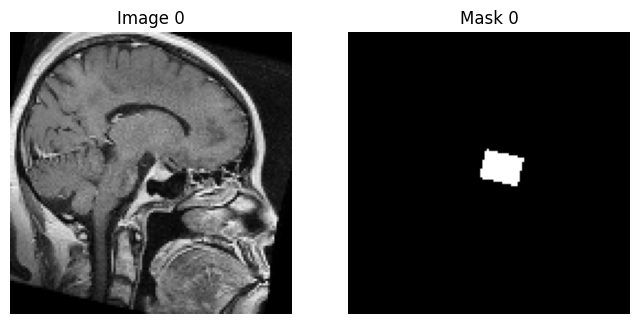

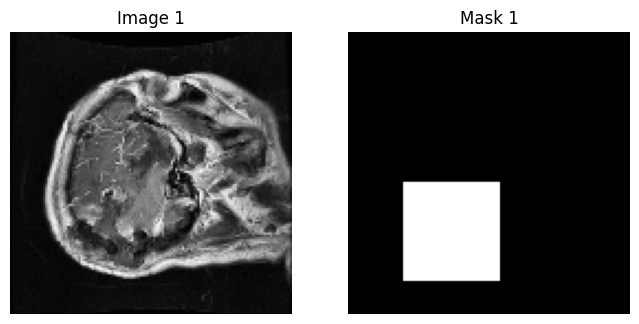

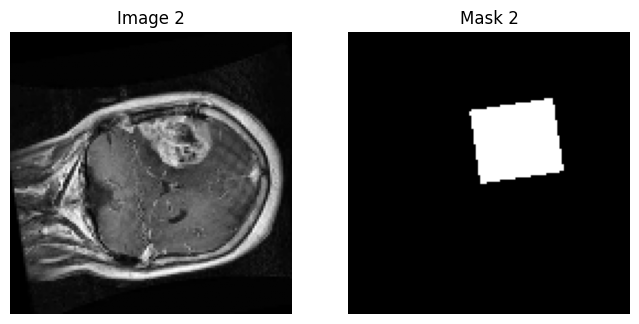

In [ ]:
# Obtiene el siguiente batch de imágenes y máscaras desde el generador de datos de entrenamiento
# imgs: batch de imágenes preprocesadas (normalizadas y con dimensiones ajustadas)
# msks: batch de máscaras correspondientes a las imágenes
imgs, msks = next(train_gen)

# Visualiza 3 ejemplos del batch
for i in range(3):  # Itera sobre los primeros 3 ejemplos del batch
    plt.figure(figsize=(8,4))  # Crea una figura con tamaño personalizado

    # --- Mostrar imagen ---
    plt.subplot(1,2,1)  # Primer subplot (1 fila, 2 columnas, posición 1)
    plt.imshow(imgs[i, ..., 0], cmap='gray')  # Muestra la imagen en escala de grises (canal único)
    plt.title(f"Image {i}")  # Título con el índice de la imagen
    plt.axis('off')  # Oculta los ejes

    # --- Mostrar máscara ---
    plt.subplot(1,2,2)  # Segundo subplot (1 fila, 2 columnas, posición 2)
    plt.imshow(msks[i, ..., 0], cmap='gray')  # Muestra la máscara correspondiente, también en escala de grises
    plt.title(f"Mask {i}")  # Título indicando el índice de la máscara
    plt.axis('off')  # Oculta los ejes

    plt.show()  # Muestra la figura con los dos subplots (imagen y su máscara)

In [ ]:
# Importa los callbacks de Keras que permiten detener el entrenamiento temprano y reducir la tasa de aprendizaje automáticamente
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --- Callback para reducir la tasa de aprendizaje cuando la validación se estanca ---
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',     # Observa la métrica 'val_loss' (pérdida en validación)
    factor=0.1,             # Reduce la tasa de aprendizaje en un factor de 10 (lr = lr * 0.1)
    patience=4,             # Espera 4 épocas sin mejora antes de reducir la tasa de aprendizaje
    min_lr=1e-5             # No baja la tasa de aprendizaje por debajo de este valor mínimo
)

# --- Callback para detener el entrenamiento si no mejora la validación ---
early_stopping = EarlyStopping(
    monitor='val_loss',         # Observa también la métrica 'val_loss'
    patience=8,                 # Espera 8 épocas sin mejora antes de detener el entrenamiento
    restore_best_weights=True  # Restaura los pesos del modelo a los de la mejor época (mínima val_loss)
)


In [ ]:
# Importa el callback ModelCheckpoint que permite guardar el modelo durante el entrenamiento
from tensorflow.keras.callbacks import ModelCheckpoint

# Importa el callback TensorBoard que permite visualizar el proceso de entrenamiento en TensorBoard
from tensorflow.keras.callbacks import TensorBoard

# --- Callback para guardar automáticamente el mejor modelo ---
checkpoint = ModelCheckpoint(
    'best_model.h5',        # Nombre del archivo donde se guardará el modelo
    save_best_only=True,    # Guarda solo el modelo con el mejor resultado en la métrica monitorizada
    monitor='val_loss'      # La métrica que se monitorea para decidir cuál modelo es el mejor (en este caso, la pérdida en validación)
)

# --- Callback para registrar logs del entrenamiento para visualizar en TensorBoard ---
tensorboard = TensorBoard(
    log_dir='./logs'        # Carpeta donde se guardarán los registros del entrenamiento
)


In [ ]:
epochs = 10

In [ ]:
history = model.fit(
    train_gen,                         # generador de datos para entrenamiento
    steps_per_epoch=steps_per_epoch,   # cuántos batches por época
    validation_data=val_gen,           # generador de datos para validación
    validation_steps=validation_steps, # batches para la validación
    epochs=epochs,                     # número total de épocas
    callbacks = [                      # callbacks para optimizar entrenamiento
    early_stopping,
    reduce_lr,
    checkpoint,
    tensorboard
]
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 975ms/step - accuracy: 0.9213 - dice_coef: 0.0539 - iou_metric: 0.0282 - loss: 0.7455

46/46 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.9220 - dice_coef: 0.0547 - iou_metric: 0.0286 - loss: 0.7437 - val_accuracy: 0.9632 - val_dice_coef: 0.2130 - val_iou_metric: 0.1194 - val_loss: 0.5335 - learning_rate: 1.0000e-04
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9627 - dice_coef: 0.2175 - iou_metric: 0.1225 - loss: 0.5269

46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 301ms/step - accuracy: 0.9626 - dice_coef: 0.2178 - iou_metric: 0.1227 - loss: 0.5268 - val_accuracy: 0.9470 - val_dice_coef: 0.2371 - val_iou_metric: 0.1347 - val_loss: 0.5186 - learning_rate: 1.0000e-04
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9363 - dice_coef: 0.2517 - iou_metric: 0.1445 - loss: 0.5040

46/46 ━━━━━━━━━━━━━━━━━━━━ 16s 348ms/step - accuracy: 0.9362 - dice_coef: 0.2519 - iou_metric: 0.1447 - loss: 0.5040 - val_accuracy: 0.9335 - val_dice_coef: 0.2779 - val_iou_metric: 0.1620 - val_loss: 0.4992 - learning_rate: 1.0000e-04
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 22s 486ms/step - accuracy: 0.9346 - dice_coef: 0.3007 - iou_metric: 0.1779 - loss: 0.4841 - val_accuracy: 0.9130 - val_dice_coef: 0.2665 - val_iou_metric: 0.1544 - val_loss: 0.5200 - learning_rate: 1.0000e-04
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.9320 - dice_coef: 0.2886 - iou_metric: 0.1693 - loss: 0.4947

46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 309ms/step - accuracy: 0.9321 - dice_coef: 0.2887 - iou_metric: 0.1694 - loss: 0.4946 - val_accuracy: 0.9235 - val_dice_coef: 0.2840 - val_iou_metric: 0.1658 - val_loss: 0.4942 - learning_rate: 1.0000e-04
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9377 - dice_coef: 0.2888 - iou_metric: 0.1698 - loss: 0.4893

46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 417ms/step - accuracy: 0.9378 - dice_coef: 0.2891 - iou_metric: 0.1700 - loss: 0.4892 - val_accuracy: 0.9394 - val_dice_coef: 0.3037 - val_iou_metric: 0.1800 - val_loss: 0.4814 - learning_rate: 1.0000e-04
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9429 - dice_coef: 0.3301 - iou_metric: 0.1987 - loss: 0.4658

46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 304ms/step - accuracy: 0.9430 - dice_coef: 0.3303 - iou_metric: 0.1988 - loss: 0.4656 - val_accuracy: 0.9534 - val_dice_coef: 0.3452 - val_iou_metric: 0.2097 - val_loss: 0.4522 - learning_rate: 1.0000e-04
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.9520 - dice_coef: 0.3830 - iou_metric: 0.2377 - loss: 0.4329

46/46 ━━━━━━━━━━━━━━━━━━━━ 23s 504ms/step - accuracy: 0.9521 - dice_coef: 0.3831 - iou_metric: 0.2377 - loss: 0.4328 - val_accuracy: 0.9610 - val_dice_coef: 0.3950 - val_iou_metric: 0.2478 - val_loss: 0.4256 - learning_rate: 1.0000e-04
Epoch 9/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9534 - dice_coef: 0.3898 - iou_metric: 0.2436 - loss: 0.4285

46/46 ━━━━━━━━━━━━━━━━━━━━ 19s 409ms/step - accuracy: 0.9535 - dice_coef: 0.3902 - iou_metric: 0.2439 - loss: 0.4282 - val_accuracy: 0.9590 - val_dice_coef: 0.4596 - val_iou_metric: 0.2996 - val_loss: 0.3836 - learning_rate: 1.0000e-04
Epoch 10/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.9604 - dice_coef: 0.4491 - iou_metric: 0.2912 - loss: 0.3879

46/46 ━━━━━━━━━━━━━━━━━━━━ 18s 397ms/step - accuracy: 0.9604 - dice_coef: 0.4491 - iou_metric: 0.2913 - loss: 0.3879 - val_accuracy: 0.9670 - val_dice_coef: 0.4695 - val_iou_metric: 0.3089 - val_loss: 0.3737 - learning_rate: 1.0000e-04


#8. Visualización de Métricas con Tensorboard


In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

# 8. Testing

In [ ]:
from pycocotools.coco import COCO

test_dir = '/content/test'
test_ann_file = os.path.join(test_dir, '_annotations.coco.json')
test_coco = COCO(test_ann_file)

test_img_ids = test_coco.getImgIds()

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━

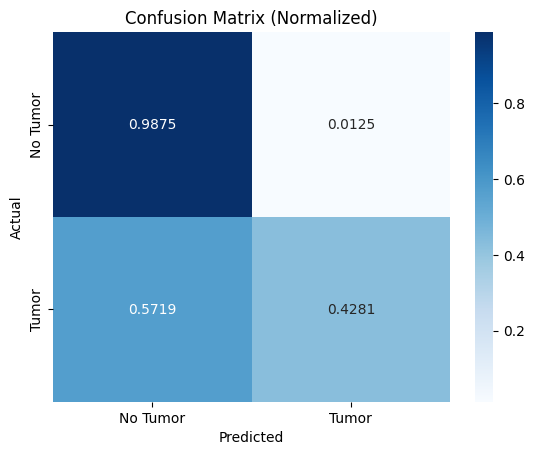

In [ ]:
# Importa la función para calcular la matriz de confusión
from sklearn.metrics import confusion_matrix
import numpy as np  # Importa NumPy para operaciones con arrays

# Inicializa listas vacías para acumular etiquetas verdaderas y predichas
y_true_all = []
y_pred_all = []

# Itera sobre todas las imágenes del conjunto de prueba
for img_id in test_img_ids:
    # Carga la imagen y su máscara real (ground truth) desde el dataset COCO
    img, true_mask = load_image_and_mask(test_coco, test_dir, img_id)

    # Preprocesa la imagen y la máscara (redimensiona, normaliza, etc.)
    img_pre, true_mask_pre = preprocess_image_and_mask(img, true_mask, img_size=(128, 128))

    # Añade una dimensión extra para simular un batch con una sola imagen
    img_input = np.expand_dims(img_pre, axis=0)

    # Usa el modelo entrenado para predecir la máscara; se toma solo la primera imagen del batch y su canal
    pred_mask = model.predict(img_input)[0, ..., 0]

    # Convierte la máscara predicha a binaria usando un umbral de 0.5, luego aplana el array
    pred_bin = (pred_mask > 0.5).astype(np.uint8).flatten()

    # Aplana también la máscara verdadera para compararla directamente
    true_bin = true_mask_pre[..., 0].astype(np.uint8).flatten()

    # Acumula los resultados en las listas correspondientes
    y_true_all.extend(true_bin)
    y_pred_all.extend(pred_bin)

# Calcula la matriz de confusión entre las etiquetas verdaderas y predichas
conf_matrix = confusion_matrix(y_true_all, y_pred_all, normalize='true')
print("Confusion Matrix:\n", conf_matrix)

# Visualiza la matriz de confusión normalizada como un mapa de calor
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    conf_matrix,
    annot=True,            # Muestra los números en las celdas
    fmt=".4f",               # Formato entero
    cmap="Blues",          # Colormap
    xticklabels=["No Tumor", "Tumor"],  # Etiquetas del eje X
    yticklabels=["No Tumor", "Tumor"]   # Etiquetas del eje Y
)
plt.xlabel("Predicted")     # Etiqueta del eje X
plt.ylabel("Actual")        # Etiqueta del eje Y
plt.title("Confusion Matrix (Normalized)")  # Título del gráfico
plt.show()  # Muestra la visualización

In [ ]:
# Convierte las listas en tensores
y_true_tensor = tf.constant(np.array(y_true_all), dtype=tf.float32)
y_pred_tensor = tf.constant(np.array(y_pred_all), dtype=tf.float32)

# Evalúa el conjunto de prueba
test_dice = dice_coef(y_true_tensor, y_pred_tensor).numpy()
test_iou  = iou_metric(y_true_tensor, y_pred_tensor).numpy()

# Retorna las métricas de evaluación del modelo en el conjunto de prueba
print(f"Test Dice (DSC) [Global]: {test_dice:.4f}")
print(f"Test IoU        [Global]: {test_iou:.4f}")

Test Dice (DSC) [Global]: 0.4874
Test IoU        [Global]: 0.3222


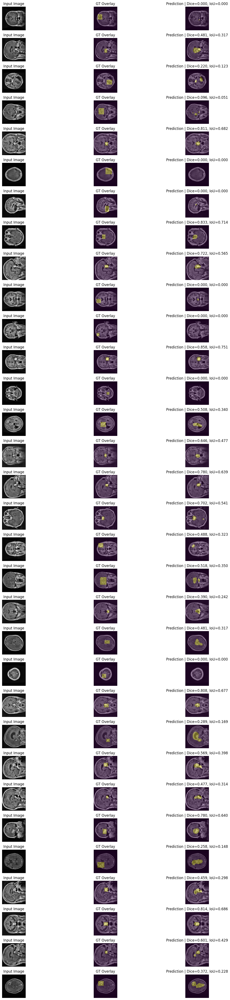

In [ ]:
# Importa el módulo para visualizar imágenes
import matplotlib.pyplot as plt

# Importa módulo para seleccionar elementos aleatoriamente
import random

# Selecciona aleatoriamente 32 IDs de imágenes del conjunto de prueba
sample_ids = random.sample(test_img_ids, 32)

# Crea una figura grande para mostrar múltiples imágenes
plt.figure(figsize=(16, 48))

# Itera sobre cada ID de imagen seleccionada
for idx, img_id in enumerate(sample_ids):

    # Carga la imagen original y su máscara verdadera (ground truth)
    img, true_mask = load_image_and_mask(test_coco, test_dir, img_id)

    # Preprocesa imagen y máscara
    img_pre, true_mask_pre = preprocess_image_and_mask(img, true_mask, img_size=(128, 128))

    # Añade dimensión batch para la predicción
    img_input = np.expand_dims(img_pre, axis=0)

    # Genera la máscara predicha usando el modelo entrenado
    pred_mask = model.predict(img_input, verbose=0)[0, ..., 0]

    # Aplica umbral para convertir la máscara predicha en binaria
    pred_bin = (pred_mask > 0.5).astype(np.float32)

    # Calcular Dice e IoU de la predicción
    y_true_img = tf.constant(true_mask_pre[np.newaxis, ...], dtype=tf.float32)
    y_pred_img = tf.constant(pred_bin[np.newaxis, ..., np.newaxis], dtype=tf.float32)

    dice_img = dice_coef(y_true_img, y_pred_img).numpy()
    iou_img  = iou_metric(y_true_img, y_pred_img).numpy()

    # Visualización

    # 1) Imagen de entrada
    plt.subplot(32, 3, idx * 3 + 1)
    plt.imshow(img_pre[..., 0], cmap='gray')
    plt.title("Input Image")
    plt.axis('off')

    # 2) Imagen + Ground Truth (overlay)
    plt.subplot(32, 3, idx * 3 + 2)
    plt.imshow(img_pre[..., 0], cmap='gray')
    plt.imshow(true_mask_pre[..., 0], alpha=0.35)
    plt.title("GT Overlay")
    plt.axis('off')

    # 3) Imagen + Predicción (overlay) + métricas
    plt.subplot(32, 3, idx * 3 + 3)
    plt.imshow(img_pre[..., 0], cmap='gray')
    plt.imshow(pred_bin, alpha=0.35)
    plt.title(f"Prediction | Dice={dice_img:.3f}, IoU={iou_img:.3f}")
    plt.axis('off')

# Ajusta los márgenes para que no se sobrepongan las imágenes
plt.tight_layout()
plt.show()